In [1]:
import pandas as pd
import numpy as np

In [3]:
# till now
# Timestamp
pd.Timestamp('6th jan 2023 8:10')
# DatetimeIndex -> df and series index
pd.DatetimeIndex([pd.Timestamp('6th jan 2023 8:10'),pd.Timestamp('7th jan 2023 8:10'),pd.Timestamp('8th jan 2023 8:10')])[0]
# date_range()
pd.date_range(start='2023-1-6',end='2023-1-31',freq='D')
# to_datetime()
s = pd.Series(['2023/1/6','2023/1/7','2023/1/7'])
pd.to_datetime(s).dt.day_name()

0      Friday
1    Saturday
2    Saturday
dtype: object

In [6]:
# Timedelta Object :-  Represents a duration, the difference between two dates or times.

# creates using Timestamp objects
t1 = pd.Timestamp('6th Jan 2023 8:20:14')
t2 = pd.Timestamp('26th Jan 2023 10:00:00')
print(t2-t1)
t1-t2




20 days 01:39:46


Timedelta('-21 days +22:20:14')

In [8]:
# standalone creation
print(pd.Timedelta(days=2,hours=10,minutes=35)) # it did not take year as input
print(pd.Timedelta(days=2,hours=10))
print(pd.Timedelta(days=2))

# as you see if do not give hour and minutes by default it take as 00

2 days 10:35:00
2 days 10:00:00
2 days 00:00:00


In [10]:
# Arithmetic :- +.-
pd.Timestamp('6th jan 2023') + pd.Timedelta(days=2,hours=10,minutes=35)

Timestamp('2023-01-08 10:35:00')

In [12]:
pd.date_range(start='2023-1-6',end='2023-1-31',freq='D') - pd.Timedelta(days=2,hours=10,minutes=35) 
# Here in every timestamp 2 days 10 hour and 35 minutes will subtracted

DatetimeIndex(['2023-01-03 13:25:00', '2023-01-04 13:25:00',
               '2023-01-05 13:25:00', '2023-01-06 13:25:00',
               '2023-01-07 13:25:00', '2023-01-08 13:25:00',
               '2023-01-09 13:25:00', '2023-01-10 13:25:00',
               '2023-01-11 13:25:00', '2023-01-12 13:25:00',
               '2023-01-13 13:25:00', '2023-01-14 13:25:00',
               '2023-01-15 13:25:00', '2023-01-16 13:25:00',
               '2023-01-17 13:25:00', '2023-01-18 13:25:00',
               '2023-01-19 13:25:00', '2023-01-20 13:25:00',
               '2023-01-21 13:25:00', '2023-01-22 13:25:00',
               '2023-01-23 13:25:00', '2023-01-24 13:25:00',
               '2023-01-25 13:25:00', '2023-01-26 13:25:00',
               '2023-01-27 13:25:00', '2023-01-28 13:25:00'],
              dtype='datetime64[ns]', freq='D')

In [15]:
# real life example
df = pd.read_csv(r"D:\Coding Language\Python\DataSet\DateTimePandaCaseStudy\deliveries.csv")
df

,order_date,delivery_date
0,5/24/98,2/5/99
1,4/22/92,3/6/98
2,2/10/91,8/26/92
3,7/21/92,11/20/97
4,9/2/93,6/10/98
...,...,...
496,6/24/91,2/2/96
497,9/9/91,3/30/98
498,11/16/90,4/27/98
499,6/3/93,6/13/93


In [17]:
# Convert them into date time object
df['order_date'] = pd.to_datetime(df['order_date'])
df['delivery_date'] = pd.to_datetime(df['delivery_date'])
df

,order_date,delivery_date
0,1998-05-24,1999-02-05
1,1992-04-22,1998-03-06
2,1991-02-10,1992-08-26
3,1992-07-21,1997-11-20
4,1993-09-02,1998-06-10
...,...,...
496,1991-06-24,1996-02-02
497,1991-09-09,1998-03-30
498,1990-11-16,1998-04-27
499,1993-06-03,1993-06-13


In [19]:
df['delivery_time_period'] = df['delivery_date'] - df['order_date']
df

,order_date,delivery_date,delivery_time_period
0,1998-05-24,1999-02-05,257 days
1,1992-04-22,1998-03-06,2144 days
2,1991-02-10,1992-08-26,563 days
3,1992-07-21,1997-11-20,1948 days
4,1993-09-02,1998-06-10,1742 days
...,...,...,...
496,1991-06-24,1996-02-02,1684 days
497,1991-09-09,1998-03-30,2394 days
498,1990-11-16,1998-04-27,2719 days
499,1993-06-03,1993-06-13,10 days


In [21]:
df['delivery_time_period'].mean()

Timedelta('1217 days 22:53:53.532934128')

### Time series

A time series is a data set that tracks a sample over time. In particular, a time series allows one to see what factors influence certain variables from period to period. Time series analysis can be useful to see how a given asset, security, or economic variable changes over time.

Examples

- Financial Data (Company stocks)
- Natural Data (Rainfall measurement)
- Event Data (Covid)
- Medical Data (Heart rate monitoring)

Types of Operations done on Time Series

- Time Series Analysis :-  Analyse Time series data.
- Time Series Forecasting :- aaj tkk k data sa predict krna kii feature mai kya hoga..

In [37]:
google = pd.read_csv(r'D:\Coding Language\Python\DataSet\DateTimePandaCaseStudy\google.csv')
google.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4471 entries, 0 to 4470
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       4471 non-null   object 
 1   Open       4471 non-null   float64
 2   High       4471 non-null   float64
 3   Low        4471 non-null   float64
 4   Close      4471 non-null   float64
 5   Adj Close  4471 non-null   float64
 6   Volume     4471 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 244.6+ KB


### These Datasets are not vailable
subs = pd.read_csv('subscribers.csv')

views = pd.read_csv('views.csv')

wt = pd.read_csv('watch-time.csv')

comments = pd.read_csv('comments.csv')
### We can do this :-
yt = subs.merge(views,on='Date').merge(wt,on='Date').merge(comments,on='Date')

### Difference between Merge and concat
merge(on='Date') aligns the rows using the Date values.

concat() simply joins by index, not by the Date column.

In [38]:
google['Date'] = pd.to_datetime(google['Date'])
google



,Date,Open,High,Low,Close,Adj Close,Volume
0,2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361
1,2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874
2,2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897
3,2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808
4,2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276
...,...,...,...,...,...,...,...
4466,2022-05-16,2307.679932,2332.149902,2286.699951,2295.850098,2295.850098,1164100
4467,2022-05-17,2344.550049,2344.550049,2306.750000,2334.030029,2334.030029,1078800
4468,2022-05-18,2304.750000,2313.913086,2242.840088,2248.020020,2248.020020,1399100
4469,2022-05-19,2236.820068,2271.750000,2209.360107,2214.909912,2214.909912,1459600


In [39]:
google.set_index('Date',inplace=True)
google

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361
2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874
2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897
2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808
2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276
...,...,...,...,...,...,...
2022-05-16,2307.679932,2332.149902,2286.699951,2295.850098,2295.850098,1164100
2022-05-17,2344.550049,2344.550049,2306.750000,2334.030029,2334.030029,1078800
2022-05-18,2304.750000,2313.913086,2242.840088,2248.020020,2248.020020,1399100


In [41]:
# fetch a specific date
google.loc['2021-12-30']



Open           2929.000000
High           2941.250000
Low            2915.169922
Close          2920.050049
Adj Close      2920.050049
Volume       648900.000000
Name: 2021-12-30 00:00:00, dtype: float64

In [43]:
# partial indexing -> select a particular year/month
google.loc['2014-12'] # Give all data of december 2022
google.loc['2014'] # Give all data of 2022

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2014-01-02,555.647278,556.788025,552.060730,554.481689,554.481689,3656454
2014-01-03,555.418152,556.379578,550.401978,550.436829,550.436829,3345894
2014-01-06,554.426880,557.340942,551.154114,556.573853,556.573853,3551864
2014-01-07,560.399475,567.717041,558.486633,567.303589,567.303589,5124336
2014-01-08,570.860291,571.517822,564.528992,568.484192,568.484192,4501811
...,...,...,...,...,...,...
2014-12-24,529.057495,530.303040,525.577026,527.322266,527.322266,705933
2014-12-26,527.322266,532.787231,525.866211,532.567810,532.567810,1040549
2014-12-29,530.732849,534.013855,528.559814,528.877991,528.877991,2278539


### create year month-name and day-name
yt['month_name'] = yt.index.month_name()

yt['weekday_name'] = yt.index.day_name()

yt['quarter'] = yt.index.quarter

In [46]:
google['month_name'] = google.index.month_name()
google['weekday_name'] = google.index.day_name()
google['quarter'] = google.index.quarter
google

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361,August,Thursday,3
2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874,August,Friday,3
2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897,August,Monday,3
2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808,August,Tuesday,3
2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276,August,Wednesday,3
...,...,...,...,...,...,...,...,...,...
2022-05-16,2307.679932,2332.149902,2286.699951,2295.850098,2295.850098,1164100,May,Monday,2
2022-05-17,2344.550049,2344.550049,2306.750000,2334.030029,2334.030029,1078800,May,Tuesday,2
2022-05-18,2304.750000,2313.913086,2242.840088,2248.020020,2248.020020,1399100,May,Wednesday,2


In [49]:
# slicing
google.loc['2004-12-15':'2006-1-1':2]

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-12-15,88.662674,90.007629,88.000153,89.554329,89.554329,23027992,December,Wednesday,4
2004-12-17,88.049965,89.912987,87.945358,89.703766,89.703766,14827771,December,Friday,4
2004-12-21,92.807137,93.589203,91.357567,91.531914,91.531914,11073953,December,Tuesday,4
2004-12-23,93.375008,93.947861,92.652718,93.599167,93.599167,7256297,December,Thursday,4
2004-12-28,95.696304,96.413620,95.148361,96.020096,96.020096,8322679,December,Tuesday,4
...,...,...,...,...,...,...,...,...,...
2005-12-16,211.875839,215.442474,210.585678,214.271851,214.271851,32783421,December,Friday,4
2005-12-20,213.131134,215.293030,211.542084,214.067627,214.067627,20245000,December,Tuesday,4
2005-12-22,215.078827,215.621796,212.169739,215.213333,215.213333,15149773,December,Thursday,4


In [ ]:
# challenge -> fetch info for a particular date every year -> limitation of timedelta
google.head()
# if we do pd.date_range(start='2005-1-6',end='2022-1-6',freq=pd.Timedelta(days=365))

# Output :- 
"""
'2005-01-06', '2006-01-06', '2007-01-06', '2008-01-06',
               '2009-01-05' ->  This is not six because of leap year
"""

# so we can't use Timedelta here

# To get correct information we use "DataOffset"

google[google.index.isin(pd.date_range(start='2005-1-6',end='2022-1-6',freq=pd.DateOffset(years=1)))]

pd.date_range(start='2005-1-6',end='2022-1-6',freq=pd.Timedelta(days=365))

DatetimeIndex(['2005-01-06', '2006-01-06', '2007-01-06', '2008-01-06',
               '2009-01-05', '2010-01-05', '2011-01-05', '2012-01-05',
               '2013-01-04', '2014-01-04', '2015-01-04', '2016-01-04',
               '2017-01-03', '2018-01-03', '2019-01-03', '2020-01-03',
               '2021-01-02', '2022-01-02'],
              dtype='datetime64[ns]', freq='365D')

<Axes: xlabel='Date'>

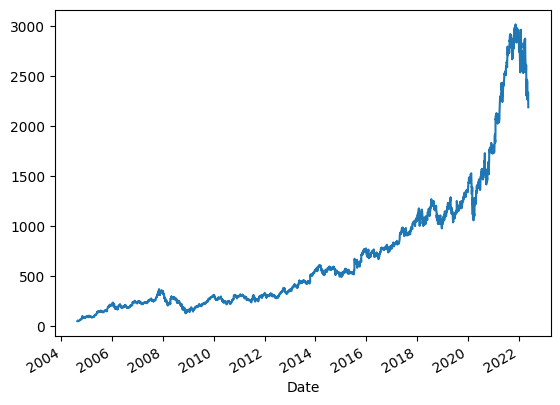

In [54]:
# viz a single col
google['Close'].plot()

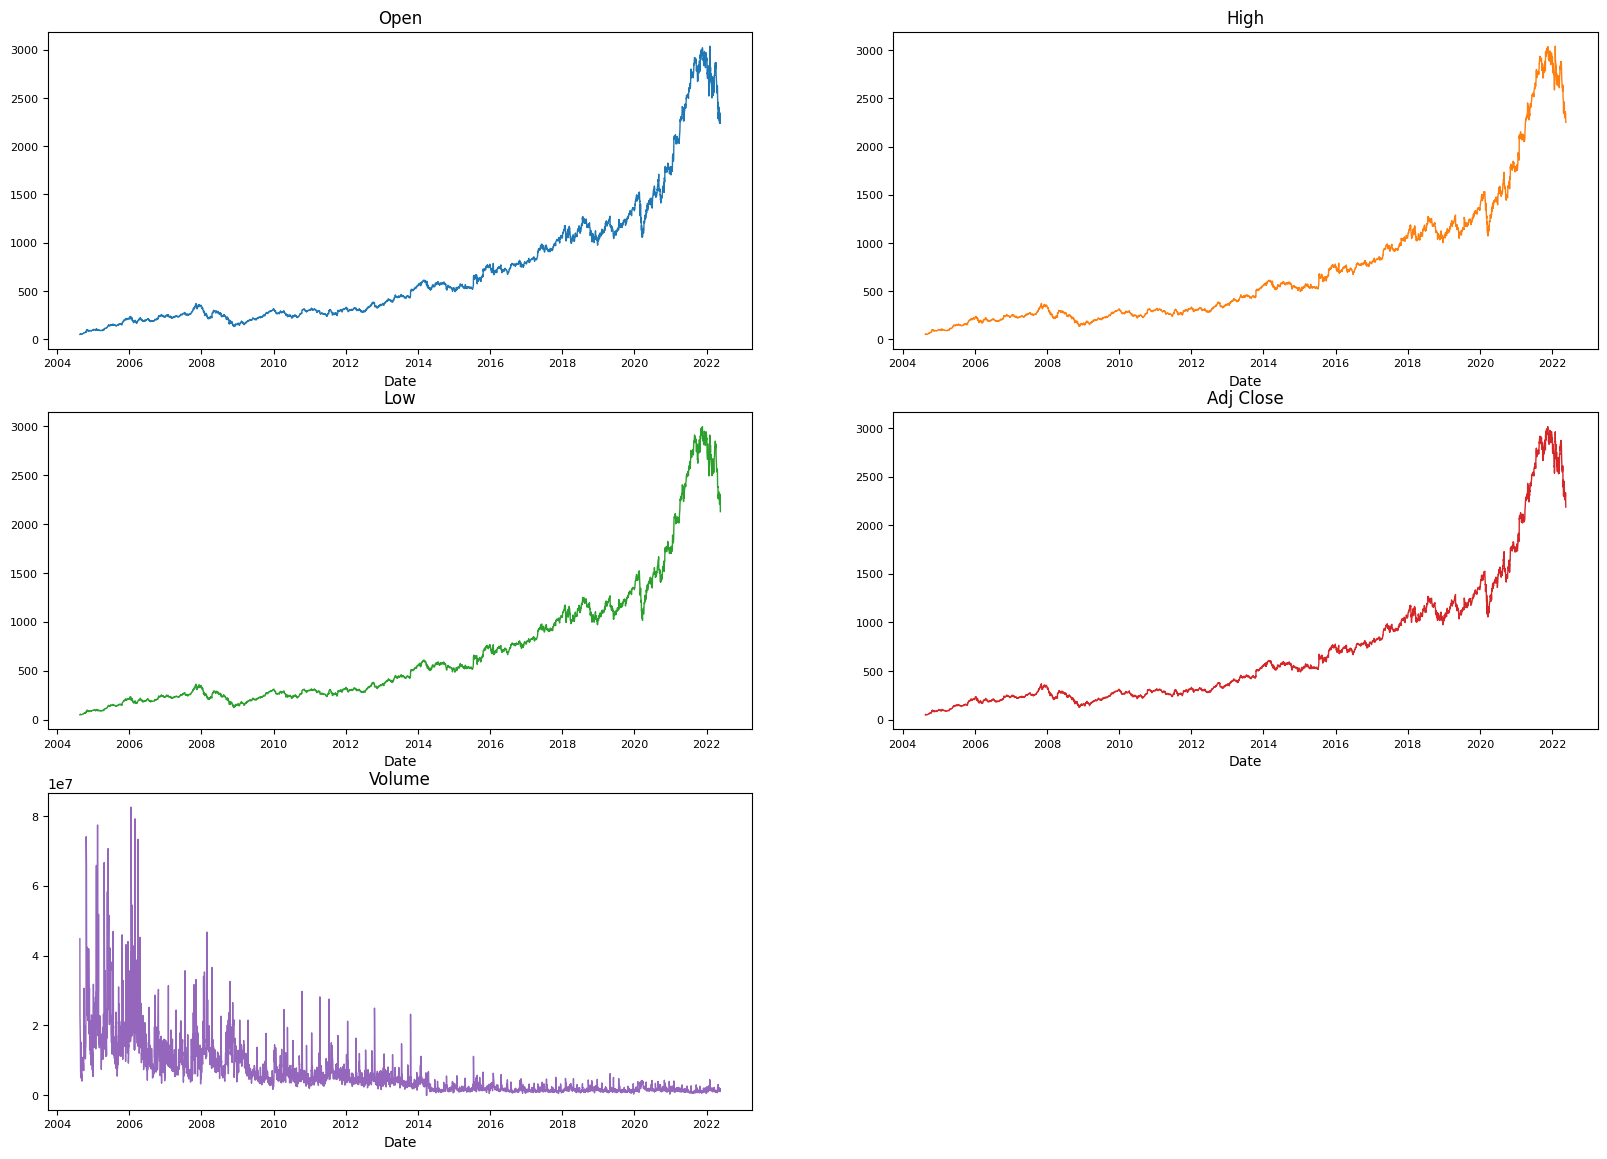

In [65]:
# viz all cols together
subset_google = google[['Open', 'High', 'Low', 'Adj Close','Volume']]
ax = subset_google.plot(subplots=True,
                    layout=(3, 2),
                     sharex=False,
                     sharey=False,
                     linewidth=1.0,
                     fontsize=8,
                     legend=False,
                     figsize=(20,14),
                      title=['Open', 'High', 'Low', 'Adj Close','Volume'])

<Axes: xlabel='Date'>

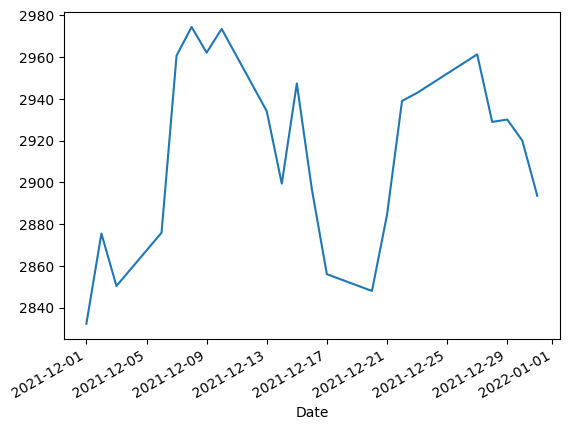

In [67]:
# plot for a particular year/month/week

google.loc['2021-12']['Close'].plot()

<Axes: xlabel='month_name'>

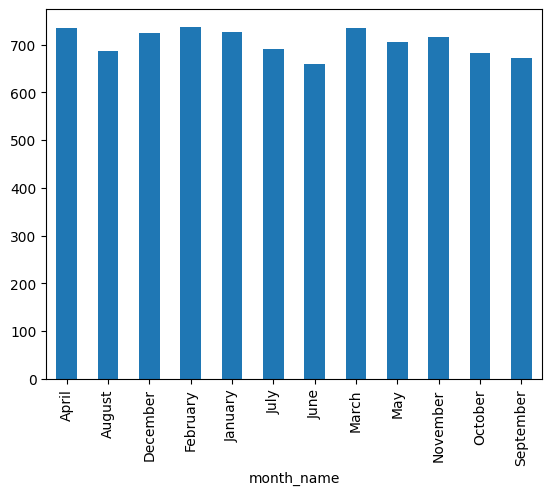

In [ ]:
# monthly trend
google.groupby('month_name')['Close'].mean().plot(kind='bar')

<Axes: xlabel='quarter'>

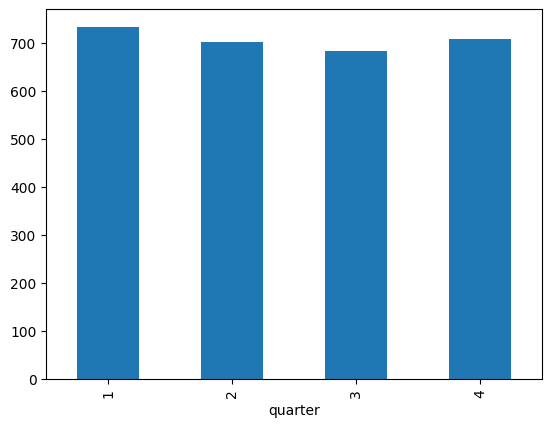

In [70]:
# quaterly trend
google.groupby('quarter')['Close'].mean().plot(kind='bar')

In [ ]:
# frequency
google.index # here you see freq = None
google.asfreq('D') # Then it gives all days . where there is no data

### Important
We  can achieve a similar result using isin() and pd.date_range(), but asfreq() exists because it is much simpler, faster, and more powerful for time series.

In [79]:
google.asfreq('B') # It gives the data of business days

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-08-19,49.813290,51.835709,47.800831,49.982655,49.982655,44871361.0,August,Thursday,3.0
2004-08-20,50.316402,54.336334,50.062355,53.952770,53.952770,22942874.0,August,Friday,3.0
2004-08-23,55.168217,56.528118,54.321388,54.495735,54.495735,18342897.0,August,Monday,3.0
2004-08-24,55.412300,55.591629,51.591621,52.239197,52.239197,15319808.0,August,Tuesday,3.0
2004-08-25,52.284027,53.798351,51.746044,52.802086,52.802086,9232276.0,August,Wednesday,3.0
...,...,...,...,...,...,...,...,...,...
2022-05-16,2307.679932,2332.149902,2286.699951,2295.850098,2295.850098,1164100.0,May,Monday,2.0
2022-05-17,2344.550049,2344.550049,2306.750000,2334.030029,2334.030029,1078800.0,May,Tuesday,2.0
2022-05-18,2304.750000,2313.913086,2242.840088,2248.020020,2248.020020,1399100.0,May,Wednesday,2.0


In [80]:
google.asfreq('Q') # It gives data quaterly.

C:\Users\prana\AppData\Local\Temp\ipykernel_6256\2787925305.py:1: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  google.asfreq('Q') # It gives data quaterly.


,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-09-30,64.707458,65.902977,64.259140,64.558022,64.558022,13823420.0,September,Thursday,3.0
2004-12-31,99.243011,99.566795,95.920464,96.035034,96.035034,15394487.0,December,Friday,4.0
2005-03-31,88.642746,90.356323,88.488327,89.917969,89.917969,13587941.0,March,Thursday,1.0
2005-06-30,146.620438,148.906860,144.976593,146.525787,146.525787,30301955.0,June,Thursday,2.0
2005-09-30,156.523315,158.157181,155.561920,157.639130,157.639130,18371203.0,September,Friday,3.0
...,...,...,...,...,...,...,...,...,...
2021-03-31,2059.120117,2093.326904,2056.745117,2068.629883,2068.629883,1459900.0,March,Wednesday,1.0
2021-06-30,2513.071045,2516.000000,2495.149902,2506.320068,2506.320068,1200300.0,June,Wednesday,2.0
2021-09-30,2686.500000,2711.800049,2660.000000,2665.310059,2665.310059,1764700.0,September,Thursday,3.0


In [82]:
google.asfreq('Y') # It gives last date of each year
# 'M' for month year

C:\Users\prana\AppData\Local\Temp\ipykernel_6256\2684415104.py:1: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  google.asfreq('Y') # It gives last date of each year


,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-12-31,99.243011,99.566795,95.920464,96.035034,96.035034,15394487.0,December,Friday,4.0
2005-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-12-31,347.980682,349.933350,344.000610,344.448914,344.448914,4770213.0,December,Monday,4.0
2008-12-31,151.532028,154.919327,150.739990,153.250580,153.250580,5795241.0,December,Wednesday,4.0
2009-12-31,311.208527,311.532288,308.832428,308.832428,308.832428,2448744.0,December,Thursday,4.0
2010-12-31,297.255798,298.092682,294.909607,295.875977,295.875977,3090139.0,December,Friday,4.0
2011-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-12-31,348.693024,353.958282,346.700470,352.369232,352.369232,4009773.0,December,Monday,4.0


In [87]:
google.asfreq('6h',method='ffill') # as we know 6H gives NaN value we can feel this by using method ='ffill' by backward values.

,Open,High,Low,Close,Adj Close,Volume,month_name,weekday_name,quarter
Date,,,,,,,,,
2004-08-19 00:00:00,49.813290,51.835709,47.800831,49.982655,49.982655,44871361,August,Thursday,3
2004-08-19 06:00:00,49.813290,51.835709,47.800831,49.982655,49.982655,44871361,August,Thursday,3
2004-08-19 12:00:00,49.813290,51.835709,47.800831,49.982655,49.982655,44871361,August,Thursday,3
2004-08-19 18:00:00,49.813290,51.835709,47.800831,49.982655,49.982655,44871361,August,Thursday,3
2004-08-20 00:00:00,50.316402,54.336334,50.062355,53.952770,53.952770,22942874,August,Friday,3
...,...,...,...,...,...,...,...,...,...
2022-05-19 00:00:00,2236.820068,2271.750000,2209.360107,2214.909912,2214.909912,1459600,May,Thursday,2
2022-05-19 06:00:00,2236.820068,2271.750000,2209.360107,2214.909912,2214.909912,1459600,May,Thursday,2
2022-05-19 12:00:00,2236.820068,2271.750000,2209.360107,2214.909912,2214.909912,1459600,May,Thursday,2


### Resampling
Resampling involves changing the frequency of your time series observations.

Two types of resampling are:

Upsampling: Where you increase the frequency of the samples, such as from minutes to seconds.

Downsampling: Where you decrease the frequency of the samples, such as from days to months. To reduce the noise.

C:\Users\prana\AppData\Local\Temp\ipykernel_6256\2660149520.py:3: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  google['Close'].resample('Y').mean().plot()


<Axes: xlabel='Date'>

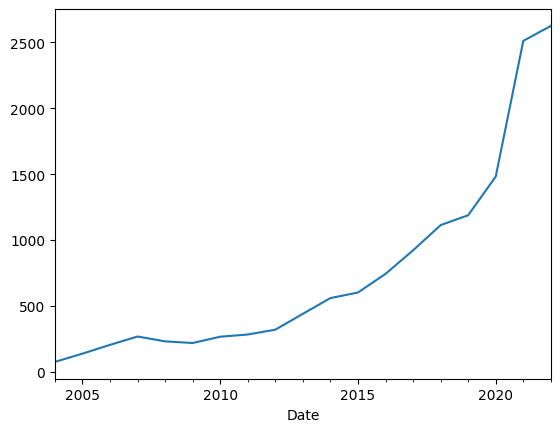

In [ ]:
# Downsampling
# google['Close'].plot() # If you draw this. There is so much noise in this. To reduce this noise we do "Downsampling".
google['Close'].resample('Y').mean().plot()  # We have to do mean() because we have to take means of data came between year.

C:\Users\prana\AppData\Local\Temp\ipykernel_6256\4126526971.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  s = google['Close'].resample('H') # Due to this NaN value are created. So we have to fill these NaN values.


<Axes: xlabel='Date'>

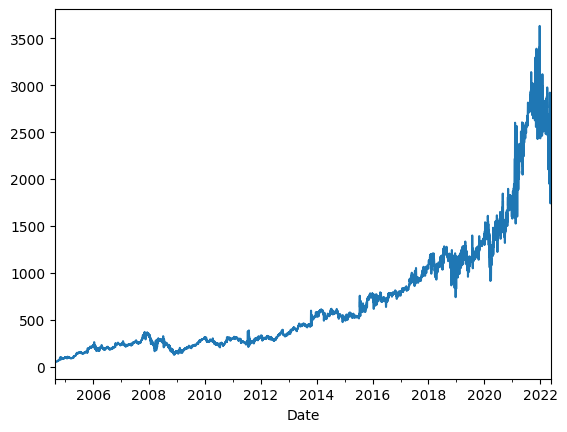

In [93]:
# Upsampling 
s = google['Close'].resample('H') # Due to this NaN value are created. So we have to fill these NaN values.
s.interpolate(method='spline',order=2).plot() # method = 'linear' or 'spline' for polynomial and order = 2.
# after upsampling you see graph become more noisy.


### Rolling Window(Smoothing)
Time series data in original format can be quite volatile, especially on smaller aggregation levels. The concept of rolling, or moving averages is a useful technique for smoothing time series data.

What is a Rolling (Moving) Average?

Instead of looking at one value at a time, we calculate the average of the last n observations.

For example, suppose the stock's closing prices are:

Day	Close Price
1	100
2	105
3	110
4	120
5	115
3-Day Rolling Average

For Day 3:


(100+105+110)/3=105

For Day 4:


(105+110+120)/3=111.67
	​

For Day 5:


(110+120+115)/3=115
	​

Result:

Day	    Close	3-Day Rolling Average

1	    100	        NaN

2	    105	        NaN

3	    110	        105.00

4	    120	        111.67

5	    115	        115.00

The first two rows are NaN because at least 3 values are needed to compute the first average.

<Axes: title={'center': 'rolling'}, xlabel='Date'>

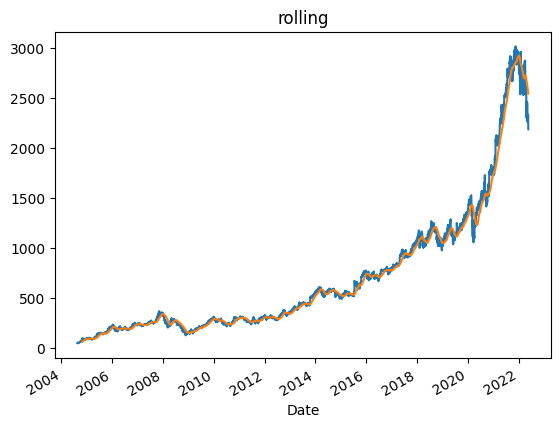

In [101]:
# Rolling window
google['Close'].plot()
google['Close'].rolling(50).mean().plot(title='rolling')


### Shifting
The shift() function is Pandas is used to, well, shift the entire series up or down by the desired number of periods.

In [ ]:
# shifting
google['Close']

Date
2004-08-19      49.982655
2004-08-20      53.952770
2004-08-23      54.495735
2004-08-24      52.239197
2004-08-25      52.802086
                 ...     
2022-05-16    2295.850098
2022-05-17    2334.030029
2022-05-18    2248.020020
2022-05-19    2214.909912
2022-05-20    2186.260010
Name: Close, Length: 4471, dtype: float64

In [105]:
# Shift Downward
google['Close'].shift(2) # Moved down by two positions . So there is 2 NaN value in starting

Date
2004-08-19            NaN
2004-08-20            NaN
2004-08-23      49.982655
2004-08-24      53.952770
2004-08-25      54.495735
                 ...     
2022-05-16    2263.219971
2022-05-17    2330.310059
2022-05-18    2295.850098
2022-05-19    2334.030029
2022-05-20    2248.020020
Name: Close, Length: 4471, dtype: float64

In [107]:
# Shift upward
google['Close'].shift(-1)

Date
2004-08-19      53.952770
2004-08-20      54.495735
2004-08-23      52.239197
2004-08-24      52.802086
2004-08-25      53.753517
                 ...     
2022-05-16    2334.030029
2022-05-17    2248.020020
2022-05-18    2214.909912
2022-05-19    2186.260010
2022-05-20            NaN
Name: Close, Length: 4471, dtype: float64

In [ ]:
# Shift Example
df1 = pd.read_csv(r"D:\Coding Language\Python\DataSet\DateTimePandaCaseStudy\login.csv",header=None) # here there is no column name so we have to do header = None
df1

# Q) Mujha ya pta krna hai kii 413 number user wala bnda ka average returning time kya hai.
# For this we have to find duration of his each subsequent visit

,0,1,2,3
0,1,466,2017-01-07 18:24:07,Unnamed: 3
1,2,466,2017-01-07 18:24:55,NaN
2,3,458,2017-01-07 18:25:18,NaN
3,4,458,2017-01-07 18:26:21,NaN
4,5,592,2017-01-07 19:09:59,NaN
...,...,...,...,...
2998,2999,1307,2018-01-04 10:48:28,183.82.121.201
2999,3000,1230,2018-01-04 11:22:00,47.247.147.114
3000,3001,1307,2018-01-04 13:13:44,183.82.121.201
3001,3002,1307,2018-01-04 13:13:45,183.82.121.201


In [117]:
df1=df1[[1,2]]
df1.rename(columns={1:'user_id',2:'login_time'},inplace=True)
df1

C:\Users\prana\AppData\Local\Temp\ipykernel_6256\1712294822.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1.rename(columns={1:'user_id',2:'login_time'},inplace=True)


,user_id,login_time
0,466,2017-01-07 18:24:07
1,466,2017-01-07 18:24:55
2,458,2017-01-07 18:25:18
3,458,2017-01-07 18:26:21
4,592,2017-01-07 19:09:59
...,...,...
2998,1307,2018-01-04 10:48:28
2999,1230,2018-01-04 11:22:00
3000,1307,2018-01-04 13:13:44
3001,1307,2018-01-04 13:13:45


In [120]:
user_df= df1[df1['user_id'] == 413]
user_df

,user_id,login_time
11,413,2017-01-09 12:29:25
12,413,2017-01-09 12:40:39
14,413,2017-01-09 14:08:04
33,413,2017-01-10 14:36:23
35,413,2017-01-10 15:22:45
...,...,...
2958,413,2017-12-29 18:20:32
2963,413,2017-12-30 13:41:21
2974,413,2018-01-01 15:16:25
2982,413,2018-01-02 18:15:45


In [122]:
user_df['login_time'] = pd.to_datetime(user_df['login_time'])
user_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 11 to 2997
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     222 non-null    int64         
 1   login_time  222 non-null    datetime64[ns]
dtypes: datetime64[ns](1), int64(1)
memory usage: 5.2 KB


C:\Users\prana\AppData\Local\Temp\ipykernel_6256\897488481.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_df['login_time'] = pd.to_datetime(user_df['login_time'])


In [125]:
user_df['shifted'] = user_df['login_time'].shift(1) # after doing this we abble to find duration by subtracting each subsequent.
user_df

C:\Users\prana\AppData\Local\Temp\ipykernel_6256\3330707987.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_df['shifted'] = user_df['login_time'].shift(1) # after doing this we abble to find duration by subtracting each subsequent.


,user_id,login_time,shifted
11,413,2017-01-09 12:29:25,NaT
12,413,2017-01-09 12:40:39,2017-01-09 12:29:25
14,413,2017-01-09 14:08:04,2017-01-09 12:40:39
33,413,2017-01-10 14:36:23,2017-01-09 14:08:04
35,413,2017-01-10 15:22:45,2017-01-10 14:36:23
...,...,...,...
2958,413,2017-12-29 18:20:32,2017-12-29 18:19:48
2963,413,2017-12-30 13:41:21,2017-12-29 18:20:32
2974,413,2018-01-01 15:16:25,2017-12-30 13:41:21
2982,413,2018-01-02 18:15:45,2018-01-01 15:16:25


In [126]:
(user_df['login_time'] - user_df['shifted']).mean() # This is the answer

Timedelta('1 days 15:05:13.384615384')